Utilisation du dispositif : cpu

--- Entraînement avec num_hiddens = 64 ---

--- Entraînement avec num_hiddens = 128 ---

--- Entraînement avec num_hiddens = 256 ---

--- Entraînement avec num_hiddens = 512 ---


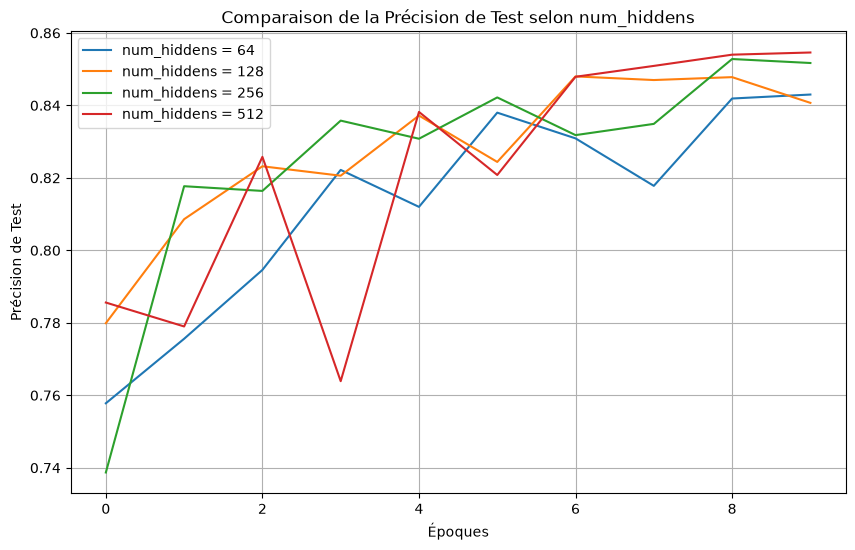


Graphique comparatif sauvegardé dans ../figures/comparison_num_hiddens.png !


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Configuration du device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation du dispositif : {device}")

# 2. Chargement du dataset Fashion-MNIST
transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(root='../data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='../data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# 3. Définition du modèle paramétrable
class FlexibleMLP(nn.Module):
    def __init__(self, num_inputs=784, num_hiddens=256, num_outputs=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_inputs, num_hiddens),
            nn.ReLU(),
            nn.Linear(num_hiddens, num_outputs)
        )

    def forward(self, X):
        return self.net(X)

# 4. Fonction d'entraînement générique
def run_experiment(net, train_loader, test_loader, epochs=10, lr=0.1):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr)
    
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    
    for epoch in range(epochs):
        net.train()
        train_loss, correct, total = 0, 0, 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = net(X)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * X.size(0)
            _, predicted = outputs.max(1)
            total += y.size(0)
            correct += predicted.eq(y).sum().item()
        
        history['train_loss'].append(train_loss / total)
        history['train_acc'].append(correct / total)
        
        # Évaluation test
        net.eval()
        test_loss, test_correct, test_total = 0, 0, 0
        with torch.no_grad():
            for X, y in test_loader:
                X, y = X.to(device), y.to(device)
                outputs = net(X)
                loss = criterion(outputs, y)
                test_loss += loss.item() * X.size(0)
                _, predicted = outputs.max(1)
                test_total += y.size(0)
                test_correct += predicted.eq(y).sum().item()
                
        history['test_loss'].append(test_loss / test_total)
        history['test_acc'].append(test_correct / test_total)
        
    return history

# 5. Campagne d'expériences : Variation de num_hiddens
hidden_sizes = [64, 128, 256, 512]
results = {}

for h_size in hidden_sizes:
    print(f"\n--- Entraînement avec num_hiddens = {h_size} ---")
    model = FlexibleMLP(num_hiddens=h_size).to(device)
    history = run_experiment(model, train_loader, test_loader, epochs=10, lr=0.1)
    results[h_size] = history

# 6. Tracé comparatif des précisions de test
plt.figure(figsize=(10, 6))
for h_size, hist in results.items():
    plt.plot(hist['test_acc'], label=f'num_hiddens = {h_size}')

plt.title("Comparaison de la Précision de Test selon num_hiddens")
plt.xlabel("Époques")
plt.ylabel("Précision de Test")
plt.legend()
plt.grid(True)
plt.savefig('../figures/comparison_num_hiddens.png')
plt.show()
print("\nGraphique comparatif sauvegardé dans ../figures/comparison_num_hiddens.png !")